# 🐍 Training Performance Analysis

# P1 — Load, Clean & Merge

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [8]:
assessments = pd.read_csv("C://Users//Asus//Mahesh_Program//Machine_Learning_Superviced_learniing//Python//assessments.csv")
assessments.head()

,assessment_id,month,course_id,batch,score,attendance_pct
0,1,Jan,C1,Morning,72,90
1,2,Jan,C2,Evening,45,70
2,3,Jan,C3,Morning,65,85
3,4,Jan,C4,Weekend,38,60
4,5,Feb,C1,Evening,80,95


In [10]:
courses = pd.read_csv("C://Users//Asus//Mahesh_Program//Machine_Learning_Superviced_learniing//Python//courses.csv")
courses.head()

,course_id,course,department
0,C1,Excel,Business
1,C2,PowerBI,Business
2,C3,SQL,Technology
3,C4,Python,Technology


In [22]:
assessments = assessments.drop_duplicates()

# Left join 
merged_df = pd.merge(assessments,courses,on="course_id",how="left")

# Assertions
assert len(merged_df) == 12
assert merged_df["department"].isna().sum() == 0

print("Total rows:", len(merged_df))
print("Unmatched courses:", merged_df["department"].isna().sum())

merged_df.head()

Total rows: 12
Unmatched courses: 0


,assessment_id,month,course_id,batch,score,attendance_pct,course,department
0,1,Jan,C1,Morning,72,90,Excel,Business
1,2,Jan,C2,Evening,45,70,PowerBI,Business
2,3,Jan,C3,Morning,65,85,SQL,Technology
3,4,Jan,C4,Weekend,38,60,Python,Technology
4,5,Feb,C1,Evening,80,95,Excel,Business


# P2 — Derived Field & Department Analysis 

In [23]:
merged_df['pass_flag'] = (merged_df['score'] >= 50).astype(int)
merged_df.head()

,assessment_id,month,course_id,batch,score,attendance_pct,course,department,pass_flag
0,1,Jan,C1,Morning,72,90,Excel,Business,1
1,2,Jan,C2,Evening,45,70,PowerBI,Business,0
2,3,Jan,C3,Morning,65,85,SQL,Technology,1
3,4,Jan,C4,Weekend,38,60,Python,Technology,0
4,5,Feb,C1,Evening,80,95,Excel,Business,1


In [26]:
department_summary = (
    merged_df.groupby("department").agg(
        total_assessments=("assessment_id", "count"),
        passing_count=("pass_flag", "sum")).reset_index())

department_summary["pass_rate_pct"] = (department_summary["passing_count"] / department_summary["total_assessments"] * 100).round(2)
print(department_summary)

   department  total_assessments  passing_count  pass_rate_pct
0    Business                  6              5          83.33
1  Technology                  6              3          50.00


In [27]:
course_summary = (merged_df.groupby("course").agg(passing_count=("pass_flag", "sum"),
                                                  total_assessments=("assessment_id", "count")).reset_index()
                 )

course_summary["pass_rate_pct"] = (
    course_summary["passing_count"] / course_summary["total_assessments"] * 100).round(2)

lowest_course = course_summary.loc[
    course_summary["pass_rate_pct"].idxmin()]

print("Course with lowest pass rate:", lowest_course["course"])
print("Numerator (passing count):", lowest_course["passing_count"])
print("Denominator (total assessments):", lowest_course["total_assessments"])
print("Lowest pass rate:", lowest_course["pass_rate_pct"], "%")

Course with lowest pass rate: Python
Numerator (passing count): 1
Denominator (total assessments): 3
Lowest pass rate: 33.33 %


# P3 — Chart & Exports

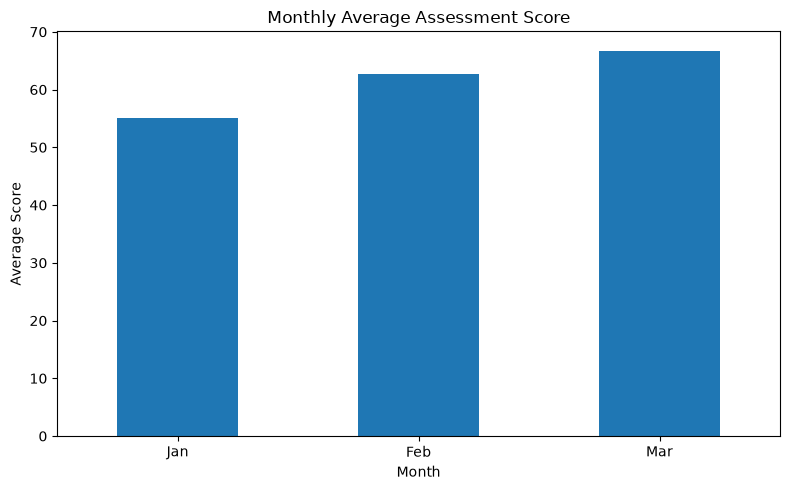

In [28]:
month_order = ["Jan", "Feb", "Mar"]
monthly_avg = (merged_df.groupby("month")["score"].mean().reindex(month_order))

plt.figure(figsize=(8, 5))
monthly_avg.plot(kind="bar")

plt.title("Monthly Average Assessment Score")
plt.xlabel("Month")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.tight_layout()

os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/python_chart.png", dpi=300)
plt.show()

In [30]:
# Export clean merged DataFrame
merged_df.to_csv("outputs/clean_data.csv", index=False)

# Export department
department_summary.to_csv("outputs/python_summary.csv", index=False)
print("All files exported successfully!")

All files exported successfully!
